# DSC212: Modularity on the Karate Club Graph

The aim of this assignment is to divide the Karate Club graph into communities using recursive spectral partitioning, and then examine the roles of individual nodes using four network metrics.

NumPy is used for the matrix calculations and eigenvectors. NetworkX provides the graph, calculates the node metrics, and helps check the modularity score. The community-detection procedure is implemented below rather than taken from a built-in function.

Run the cells in order. The first cell installs any missing packages, which requires an internet connection. The graph is included with NetworkX, and the figures and tables are saved in `results/`. Nodes are numbered from 0 to 33.

## 1. Setup and data
The 34 vertices represent club members and the 78 edges represent friendships. The historical `club` attribute is used only for evaluation, never to construct the partition. NetworkX includes edge weights, but the assignment specifies a binary adjacency matrix, so we explicitly discard those weights.

In [1]:
# Install missing dependencies using the Python interpreter of this notebook.
import importlib
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "networkx": "networkx",
    "IPython": "ipython",
}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    print("Installing missing packages:", ", ".join(missing_packages), flush=True)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install",
                               "--quiet", *missing_packages])
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(
            "Package installation failed. Check internet access and the pip message above. "
            "If Python is externally managed, select a virtual-environment kernel "
            "with the packages in requirements.txt installed, then rerun from the first cell."
        ) from exc
    importlib.invalidate_caches()
print("Dependency check complete.")


Dependency check complete.


In [2]:
from pathlib import Path
import sys
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import networkx as nx
from IPython.display import display

OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 180,
                     "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
TOL = 1e-10
SEED = 42

G = nx.karate_club_graph()
for _, _, data in G.edges(data=True):
    data.pop("weight", None)       # Binary/unweighted graph throughout.
nodes = sorted(G.nodes())
index = {node: i for i, node in enumerate(nodes)}
n, m = G.number_of_nodes(), G.number_of_edges()
A = nx.to_numpy_array(G, nodelist=nodes, weight=None, dtype=float)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)
assert (n, m) == (34, 78)
assert np.isclose(k.sum(), 2*m)
assert np.allclose(B, B.T)
assert np.allclose(B @ np.ones(n), 0)
print(f"Graph: {n} nodes, {m} unweighted edges; connected: {nx.is_connected(G)}")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"NetworkX {nx.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Graph: 34 nodes, 78 unweighted edges; connected: True
Python 3.12.14 | NumPy 2.3.5 | NetworkX 3.7 | pandas 2.2.3 | Matplotlib 3.10.8


## 2. Method
Modularity compares observed within-community edges with a degree-based random baseline:
$$B=A-kk^\top/(2m),\qquad Q=\sum_C[L_C/m-(K_C/(2m))^2].$$
Here $L_C$ counts internal edges once and $K_C$ sums original-graph degrees in community $C$.

For a candidate community, use $R=B[C,C]$ and the corrected matrix
$$M_C=R-\operatorname{diag}(R\mathbf1),\qquad \Delta Q=s^\top M_Cs/(4m).$$
The signs of the leading eigenvector propose two groups. Accept them only when both are nonempty and the actual gain is positive. Original degrees and $m$ remain fixed throughout recursion. One iteration records one accepted split. The derivation and stopping-rule justification appear in Appendix A.

**Functions below:** `modularity_from_scratch(partition)` returns the global score; `corrected_block(C)` returns the restricted and corrected matrices; `propose_split(C)` returns the candidate children, leading eigenvalue, gain, and acceptance/rejection reason.

In [3]:
def modularity_from_scratch(partition):
    """Q using original degrees and edge count (valid for any number of groups)."""
    return float(sum(
        G.subgraph(C).number_of_edges()/m
        - (sum(G.degree(v) for v in C)/(2*m))**2
        for C in partition
    ))


def corrected_block(C):
    """Global B restricted to C, with the diagonal row-sum correction."""
    ids = [index[v] for v in C]
    R = B[np.ix_(ids, ids)]
    return R, R - np.diag(R.sum(axis=1))


def propose_split(C):
    C = tuple(sorted(C))
    R, M = corrected_block(C)
    assert np.allclose(M.sum(axis=1), 0)
    values, vectors = np.linalg.eigh(M)  # Real symmetric eigensolver; ascending order.
    leading = float(values[-1])
    u = vectors[:, -1].copy()
    pivot = int(np.argmax(np.abs(u)))
    if u[pivot] < 0:                    # Eigenvectors u and -u are equivalent.
        u = -u
    signs = np.where(u > 0, 1, -1)     # An exact zero goes to the negative side.
    children = [tuple(v for v, z in zip(C, signs) if z == label)
                for label in (1, -1)]
    gain = float(signs @ M @ signs / (4*m))
    if len(C) < 2:
        reason = "singleton"
    elif leading <= TOL:
        reason = "nonpositive leading eigenvalue"
    elif any(len(child) == 0 for child in children):
        reason = "empty sign group"
    elif gain <= TOL:
        reason = "nonpositive rounded gain"
    else:
        reason = "accepted"
    children = sorted(children, key=lambda child: child[0] if child else -1)
    return children, leading, gain, reason

## 3. Splitting the communities

The groups are stored in a dictionary. The starting group is called `C`. Its children are `C0` and `C1`, and splitting `C0` gives `C00` and `C01`.

The function `visit` tests a group, records the partition if the split is accepted, and repeats the process for the two children. It returns the final groups, the split history, and the attempted splits. The original graph keeps all its edges.

In [4]:
def recursive_spectral_partition():
    partition = {"C": tuple(nodes)}
    history = [{"iteration": 0, "split": "initial", "gain": 0.0,
                "Q": modularity_from_scratch(partition.values()),
                "communities": dict(partition)}]
    attempts = []

    def visit(cid):
        C = partition[cid]
        children, leading, gain, reason = propose_split(C)
        attempts.append({"community": cid, "size": len(C),
                         "nodes": list(C), "lambda_max": leading,
                         "candidate_gain": gain, "decision": reason})
        if reason != "accepted":
            return
        before = modularity_from_scratch(partition.values())
        del partition[cid]
        for j, child in enumerate(children):
            partition[cid + str(j)] = child
        after = modularity_from_scratch(partition.values())
        assert after > before + TOL
        assert np.isclose(after-before, gain, atol=1e-12)
        assert np.isclose(after, nx.community.modularity(
            G, list(partition.values()), weight=None), atol=1e-12)
        history.append({"iteration": len(history), "split": cid,
                        "gain": after-before, "Q": after,
                        "communities": dict(partition)})
        for j in range(2):
            visit(cid + str(j))

    visit("C")
    return partition, history, pd.DataFrame(attempts)

final_partition, history, attempts = recursive_spectral_partition()
summary = pd.DataFrame([
    {"iteration": h["iteration"], "split": h["split"],
     "communities": len(h["communities"]), "gain": h["gain"], "Q": h["Q"]}
    for h in history])
display(summary.round(8))
display(attempts.drop(columns="nodes").round(8))
display(pd.DataFrame([
    {"community": cid, "size": len(C), "nodes": list(C)}
    for cid, C in sorted(final_partition.items())]))

,iteration,split,communities,gain,Q
0,0,initial,1,0.000000,0.000000
1,1,C,2,0.371466,0.371466
2,2,C0,3,0.001233,0.372699
3,3,C1,4,0.020710,0.393409


,community,size,lambda_max,candidate_gain,decision
0,C,34,4.977080,0.371466,accepted
1,C0,16,1.178538,0.001233,accepted
2,C00,7,-0.000000,-0.000000,nonpositive leading eigenvalue
3,C01,9,0.060191,-0.015779,nonpositive rounded gain
4,C1,18,0.859415,0.020710,accepted
5,C10,12,-0.000000,0.000000,nonpositive leading eigenvalue
6,C11,6,0.000000,0.000000,nonpositive leading eigenvalue


,community,size,nodes
0,C00,7,"[0, 4, 5, 6, 10, 11, 16]"
1,C01,9,"[1, 2, 3, 7, 12, 13, 17, 19, 21]"
2,C10,12,"[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]"
3,C11,6,"[23, 24, 25, 27, 28, 31]"


## 4. Checking the result

The checks below confirm that every node appears in exactly one group and that the modularity calculations agree. The historical club labels are then compared with the first split. These labels are not used to choose the communities. Further checks are included in Appendix B.

In [5]:
for h in history:
    groups = list(h["communities"].values())
    flat = [v for C in groups for v in C]
    assert sorted(flat) == nodes and len(flat) == len(set(flat))
    q_matrix = sum(B[np.ix_([index[v] for v in C],
                           [index[v] for v in C])].sum() for C in groups)/(2*m)
    assert np.isclose(h["Q"], q_matrix)
    assert np.isclose(h["Q"], nx.community.modularity(G, groups, weight=None))
assert np.all(np.diff(summary["Q"]) > TOL)

# Club labels are used only now, after detection.
truth = [set(v for v in nodes if G.nodes[v]["club"] == label)
         for label in ("Mr. Hi", "Officer")]
first = list(history[1]["communities"].values())
# Match the two arbitrary predicted labels to the two observed labels.
if len(set(first[0]) & truth[0]) + len(set(first[1]) & truth[1]) >= n/2:
    matched = first
else:
    matched = first[::-1]
mismatches = sorted(set(matched[0]) ^ truth[0])
print(f"First split agrees with club labels for {n-len(mismatches)}/{n} nodes.")
print("Mismatched node IDs:", mismatches)
print(f"Historical two-group modularity: {modularity_from_scratch(truth):.8f}")

First split agrees with club labels for 33/34 nodes.
Mismatched node IDs: [8]
Historical two-group modularity: 0.35823471


## 5. Graph after every accepted split
All panels retain all 78 original edges and reuse exactly the same spring-layout coordinates. Dashed grey edges cross the current community boundaries; solid edges remain within a community. Colours identify the community IDs shown in each legend; the larger child keeps the parent colour and the smaller child receives a new colour (ties use the lowest node ID). Positions and node labels stay fixed.

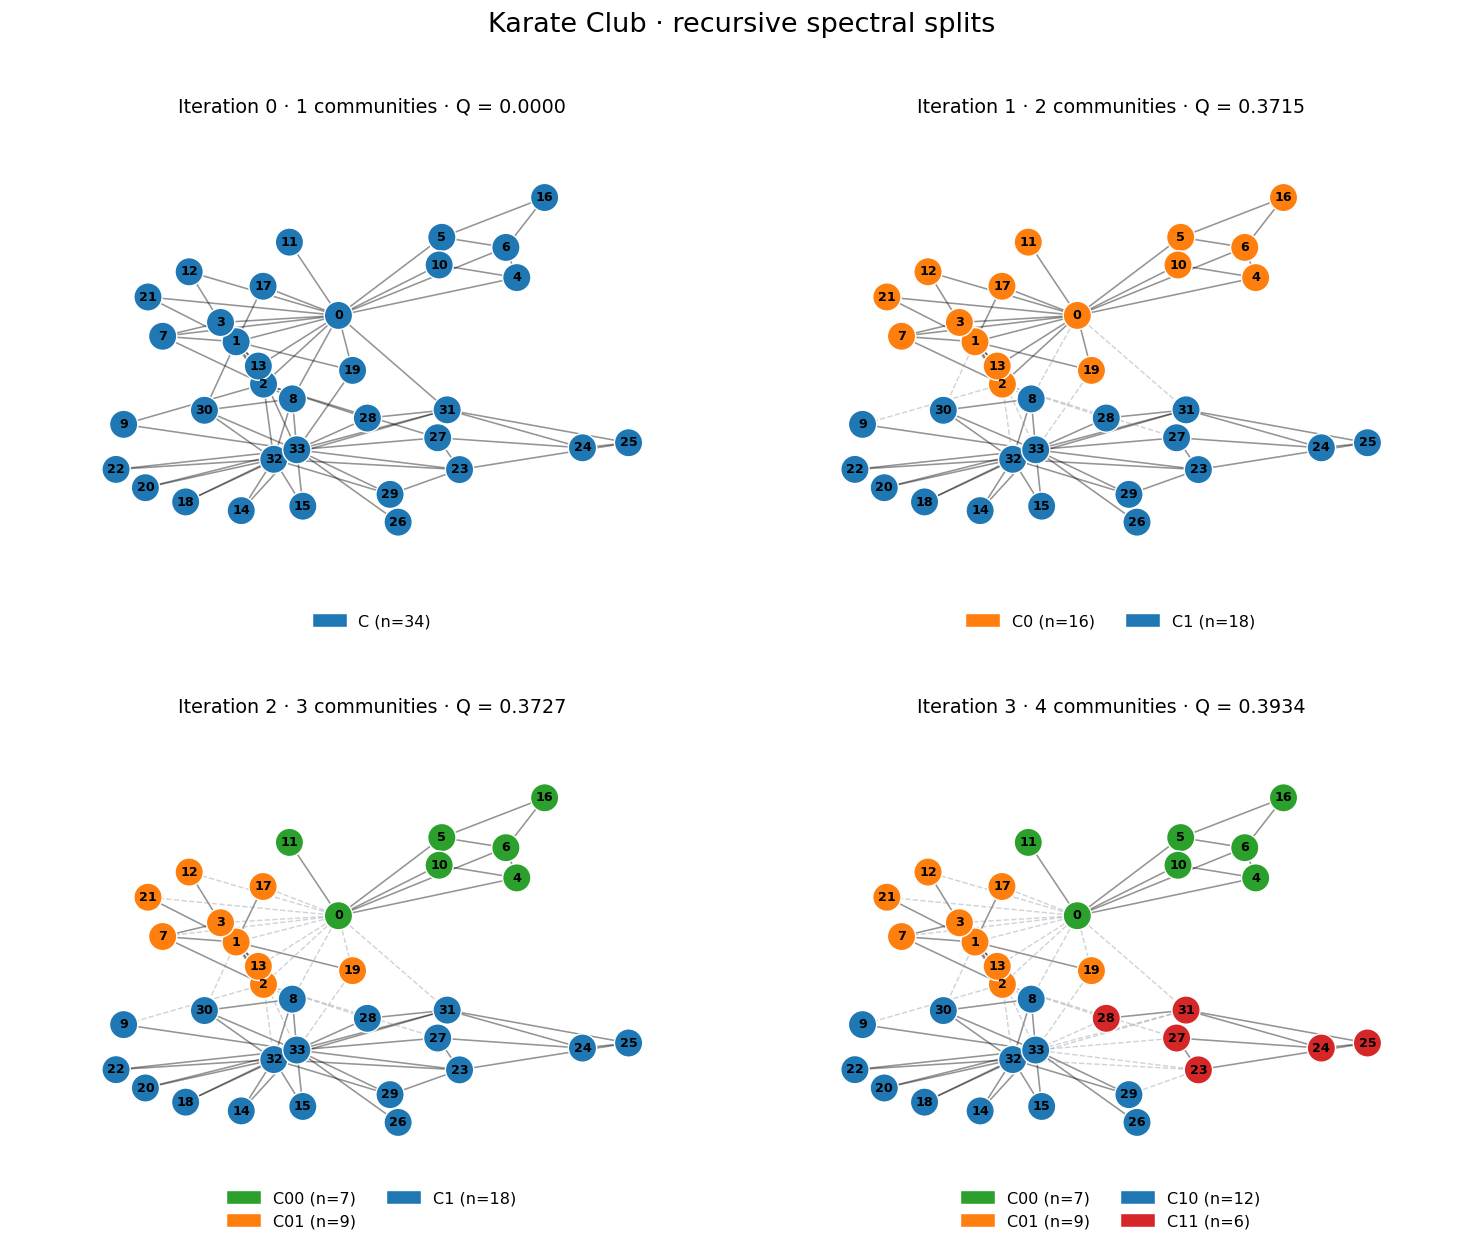

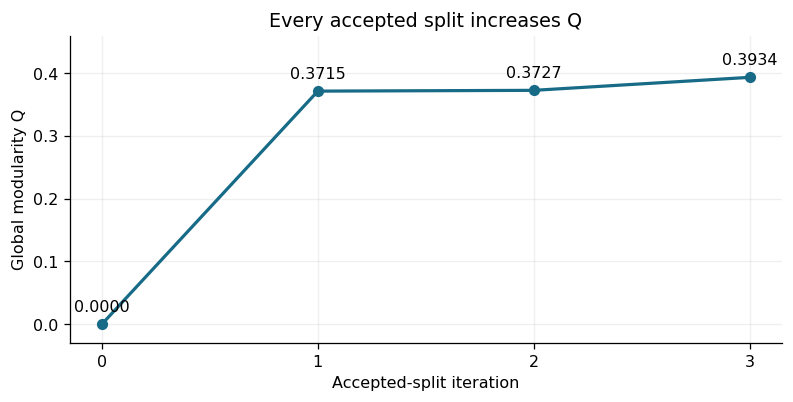

In [6]:
pos = nx.spring_layout(G, seed=SEED, weight=None)
# Larger child inherits its parent's colour; ties use the lowest node ID.
palette = plt.get_cmap("tab10")
community_color = {"C": palette(0)}
next_color = 1
for snapshot in history[1:]:
    parent = snapshot["split"]
    children = [parent + "0", parent + "1"]
    children.sort(key=lambda cid: (-len(snapshot["communities"][cid]),
                                   min(snapshot["communities"][cid])))
    community_color[children[0]] = community_color[parent]
    community_color[children[1]] = palette(next_color)
    next_color += 1

def draw_partition(h, ax):
    groups = h["communities"]
    owner = {v: cid for cid, C in groups.items() for v in C}
    inside = [(u,v) for u,v in G.edges() if owner[u] == owner[v]]
    outside = [(u,v) for u,v in G.edges() if owner[u] != owner[v]]
    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, width=1.0, alpha=.42)
    nx.draw_networkx_edges(G, pos, edgelist=outside, ax=ax, width=.9,
                           edge_color="#8893a1", style="dashed", alpha=.40)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax, node_size=315,
                          node_color=[community_color[owner[v]] for v in nodes],
                          edgecolors="white", linewidths=.9)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight="bold")
    ax.set_title(f"Iteration {h['iteration']} · {len(groups)} communities · Q = {h['Q']:.4f}", pad=12)
    ax.legend(handles=[Patch(color=community_color[cid], label=f"{cid} (n={len(C)})")
                       for cid,C in sorted(groups.items())],
              loc="lower center", bbox_to_anchor=(.5,-.12), ncol=2, frameon=False)
    ax.margins(.14); ax.set_axis_off()

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for h, ax in zip(history, axes.flat):
    draw_partition(h, ax)
for ax in list(axes.flat)[len(history):]:
    ax.set_axis_off()
fig.suptitle("Karate Club · recursive spectral splits", fontsize=17)
fig.tight_layout(rect=(0,0,1,.96), h_pad=4)
fig.savefig(OUT / "community_splits.png", bbox_inches="tight")
plt.show()
for h in history:
    fig, ax = plt.subplots(figsize=(8,7))
    draw_partition(h, ax)
    fig.savefig(OUT / f"split_{h['iteration']:02d}.png", bbox_inches="tight")
    plt.close(fig)

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(summary["iteration"], summary["Q"], "o-", color="#176b87", linewidth=2)
for _, row in summary.iterrows():
    ax.annotate(f"{row['Q']:.4f}", (row["iteration"], row["Q"]),
                xytext=(0,8), textcoords="offset points", ha="center")
ax.set(xlabel="Accepted-split iteration", ylabel="Global modularity Q",
       xticks=summary["iteration"], ylim=(-.03,.46), title="Every accepted split increases Q")
ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT / "modularity_evolution.png"); plt.show()

## 6. Measuring the node metrics

**Global view:** recompute all four metrics on $G$ after each split. Since the edges and vertices of $G$ do not change, these values must remain constant. A community label is not an input to these metric functions.

**Community view:** for node $v$ in its current community $C$, compute its metrics on the induced subgraph $G[C]$. This asks how central $v$ is **within that group**, and produces meaningful changes as groups split. Cross-community friendships still exist in $G$; they are simply excluded from this local measurement. This gives the within-community measurements used in the plots.

For the graph $H$ on which a metric is measured, let $N=|V(H)|$, $d_v$ be its degree, and $r$ the number of vertices reachable from $v$, excluding $v$.

| Metric | Formula / convention | Interpretation |
|---|---|---|
| Degree centrality | $d_v/(N-1)$ | Fraction of other vertices directly adjacent |
| Betweenness | $\frac{2}{(N-1)(N-2)}\sum_{s<t;\ s,t\ne v}\sigma_{st}(v)/\sigma_{st}$ | Fraction of shortest-path pairs brokered; unreachable pairs contribute zero |
| Closeness | $\frac{r}{N-1}\frac{r}{\sum_{u\text{ reachable}}d(v,u)}$ | Reachability-adjusted inverse distance (`wf_improved=True`) |
| Clustering | $2T_v/[d_v(d_v-1)]$ | Fraction of neighbour pairs joined by an edge |

Betweenness is normalized with endpoints excluded. Clustering is zero for degree below two. We explicitly assign zero metrics to a singleton and zero betweenness for $N<3$. All paths are unweighted. For connected $H$, closeness simplifies to $(N-1)/\sum_{u\ne v}d(v,u)$.

**Comparison caveat:** community size changes the normalization of degree, betweenness, and closeness. A larger local score need not mean more influence over the entire club. Clustering is cohesion, not a general influence score.

**Function below:** `node_metrics(H)` takes the graph being measured and returns four dictionaries indexed by node ID. It is applied to the full graph and separately to each current community.

In [7]:
METRICS = ["degree", "betweenness", "closeness", "clustering"]
LABELS = {"degree": "Degree centrality", "betweenness": "Betweenness centrality",
          "closeness": "Closeness centrality", "clustering": "Clustering coefficient"}

def node_metrics(H):
    if len(H) <= 1:
        return {metric: {v: 0.0 for v in H} for metric in METRICS}
    return {
        "degree": nx.degree_centrality(H),
        "betweenness": nx.betweenness_centrality(H, normalized=True, weight=None,
                                                endpoints=False),
        "closeness": nx.closeness_centrality(H, distance=None, wf_improved=True),
        "clustering": nx.clustering(H, weight=None),
    }

# Dictionaries keyed by iteration, then metric, then node ID.
global_metrics, local_metrics = {}, {}
records = []
for h in history:
    t = h["iteration"]
    global_metrics[t] = node_metrics(G)
    local_metrics[t] = {metric: {} for metric in METRICS}
    owner = {v: cid for cid,C in h["communities"].items() for v in C}
    for cid, C in h["communities"].items():
        values = node_metrics(G.subgraph(C))
        for metric in METRICS:
            local_metrics[t][metric].update(values[metric])
    for scope, bank in [("global", global_metrics), ("within_community", local_metrics)]:
        for v in nodes:
            records.append({"scope": scope, "iteration": t, "node": v,
                            "community": owner[v],
                            "community_size": len(h["communities"][owner[v]]),
                            **{metric: bank[t][metric][v] for metric in METRICS}})
metrics_df = pd.DataFrame(records)
for metric in METRICS:
    assert all(np.allclose(list(global_metrics[t][metric].values()),
                           list(global_metrics[0][metric].values())) for t in global_metrics)
    assert np.allclose([global_metrics[0][metric][v] for v in nodes],
                       [local_metrics[0][metric][v] for v in nodes])
assert np.isfinite(metrics_df[METRICS].to_numpy()).all()
assert metrics_df[METRICS].ge(-TOL).all().all()
assert metrics_df[METRICS].le(1+TOL).all().all()
print(f"Computed {len(metrics_df)} node-iteration-scope rows; each contains all four metrics.")
last_iteration = history[-1]["iteration"]
final_metrics = metrics_df[(metrics_df["scope"] == "within_community")
                           & (metrics_df["iteration"] == last_iteration)]
display(final_metrics.round(4).reset_index(drop=True))

Computed 272 node-iteration-scope rows; each contains all four metrics.


,scope,iteration,node,community,community_size,degree,betweenness,closeness,clustering
0,within_community,3,0,C00,7,0.8333,0.3778,0.8571,0.4000
1,within_community,3,1,C01,9,0.8750,0.6548,0.8889,0.2381
2,within_community,3,2,C01,9,0.5000,0.0119,0.6667,0.8333
3,within_community,3,3,C01,9,0.6250,0.2619,0.7273,0.5000
4,within_community,3,4,C00,7,0.5000,0.0222,0.6667,0.6667
5,within_community,3,5,C00,7,0.6667,0.1556,0.7500,0.5000
6,within_community,3,6,C00,7,0.6667,0.1556,0.7500,0.5000
7,within_community,3,7,C01,9,0.3750,0.0000,0.6154,1.0000
8,within_community,3,8,C10,12,0.2727,0.0000,0.5789,1.0000
9,within_community,3,9,C10,12,0.0909,0.0000,0.5238,0.0000


## 7. Evolution plots: all 34 nodes
Each metric has one small panel per node, with consistent node IDs and iteration ticks. The blue line measures the current community; the dashed orange line measures the original graph. If the curves coincide, the dashed line may cover the blue line. A second overview tracks six selected nodes for a closer comparison.

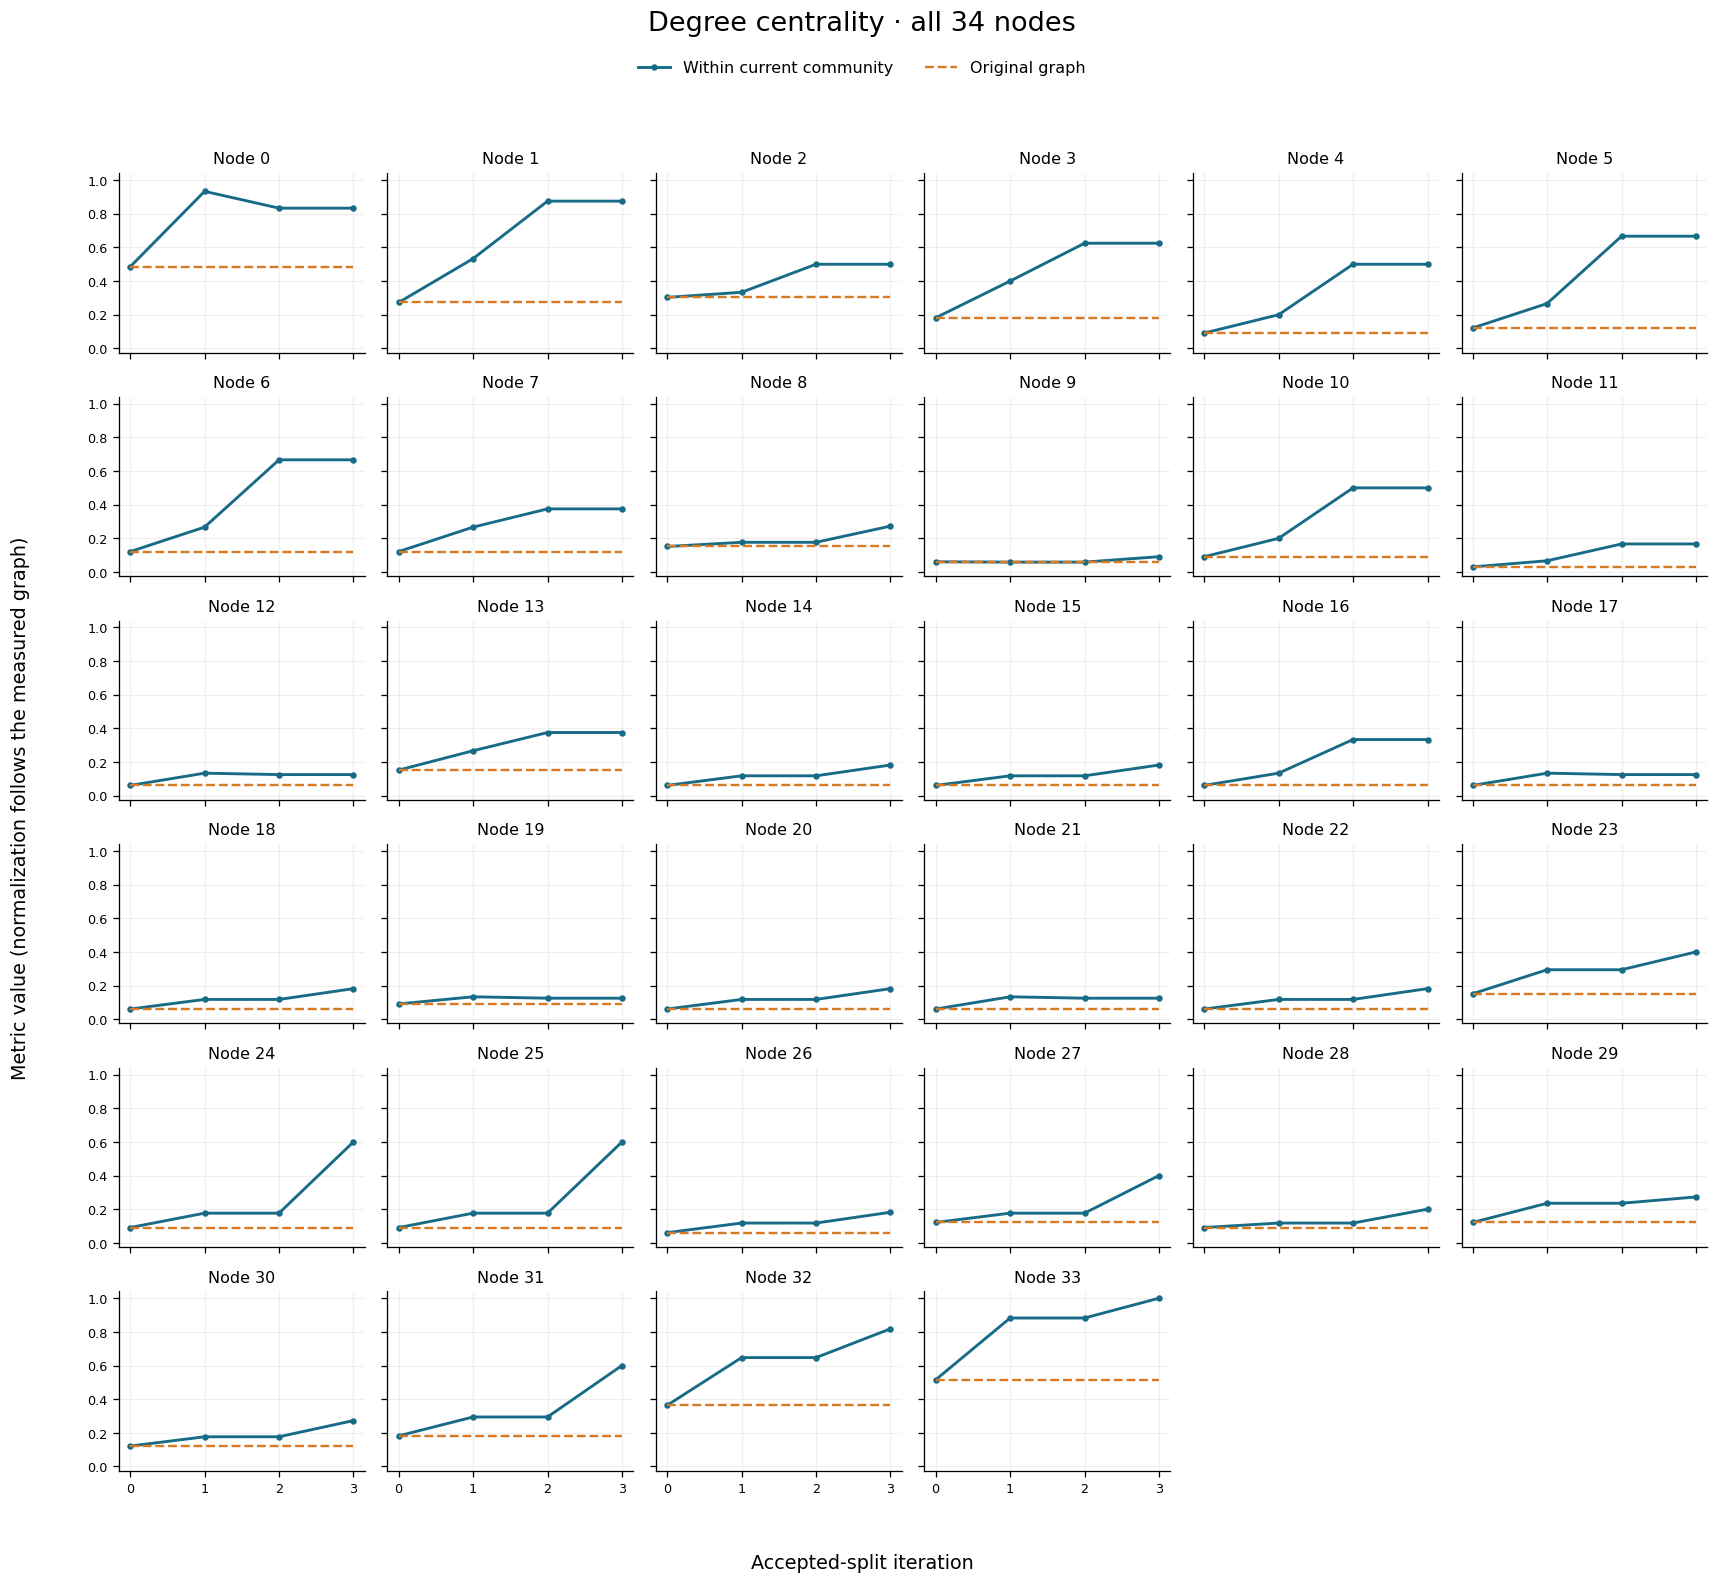

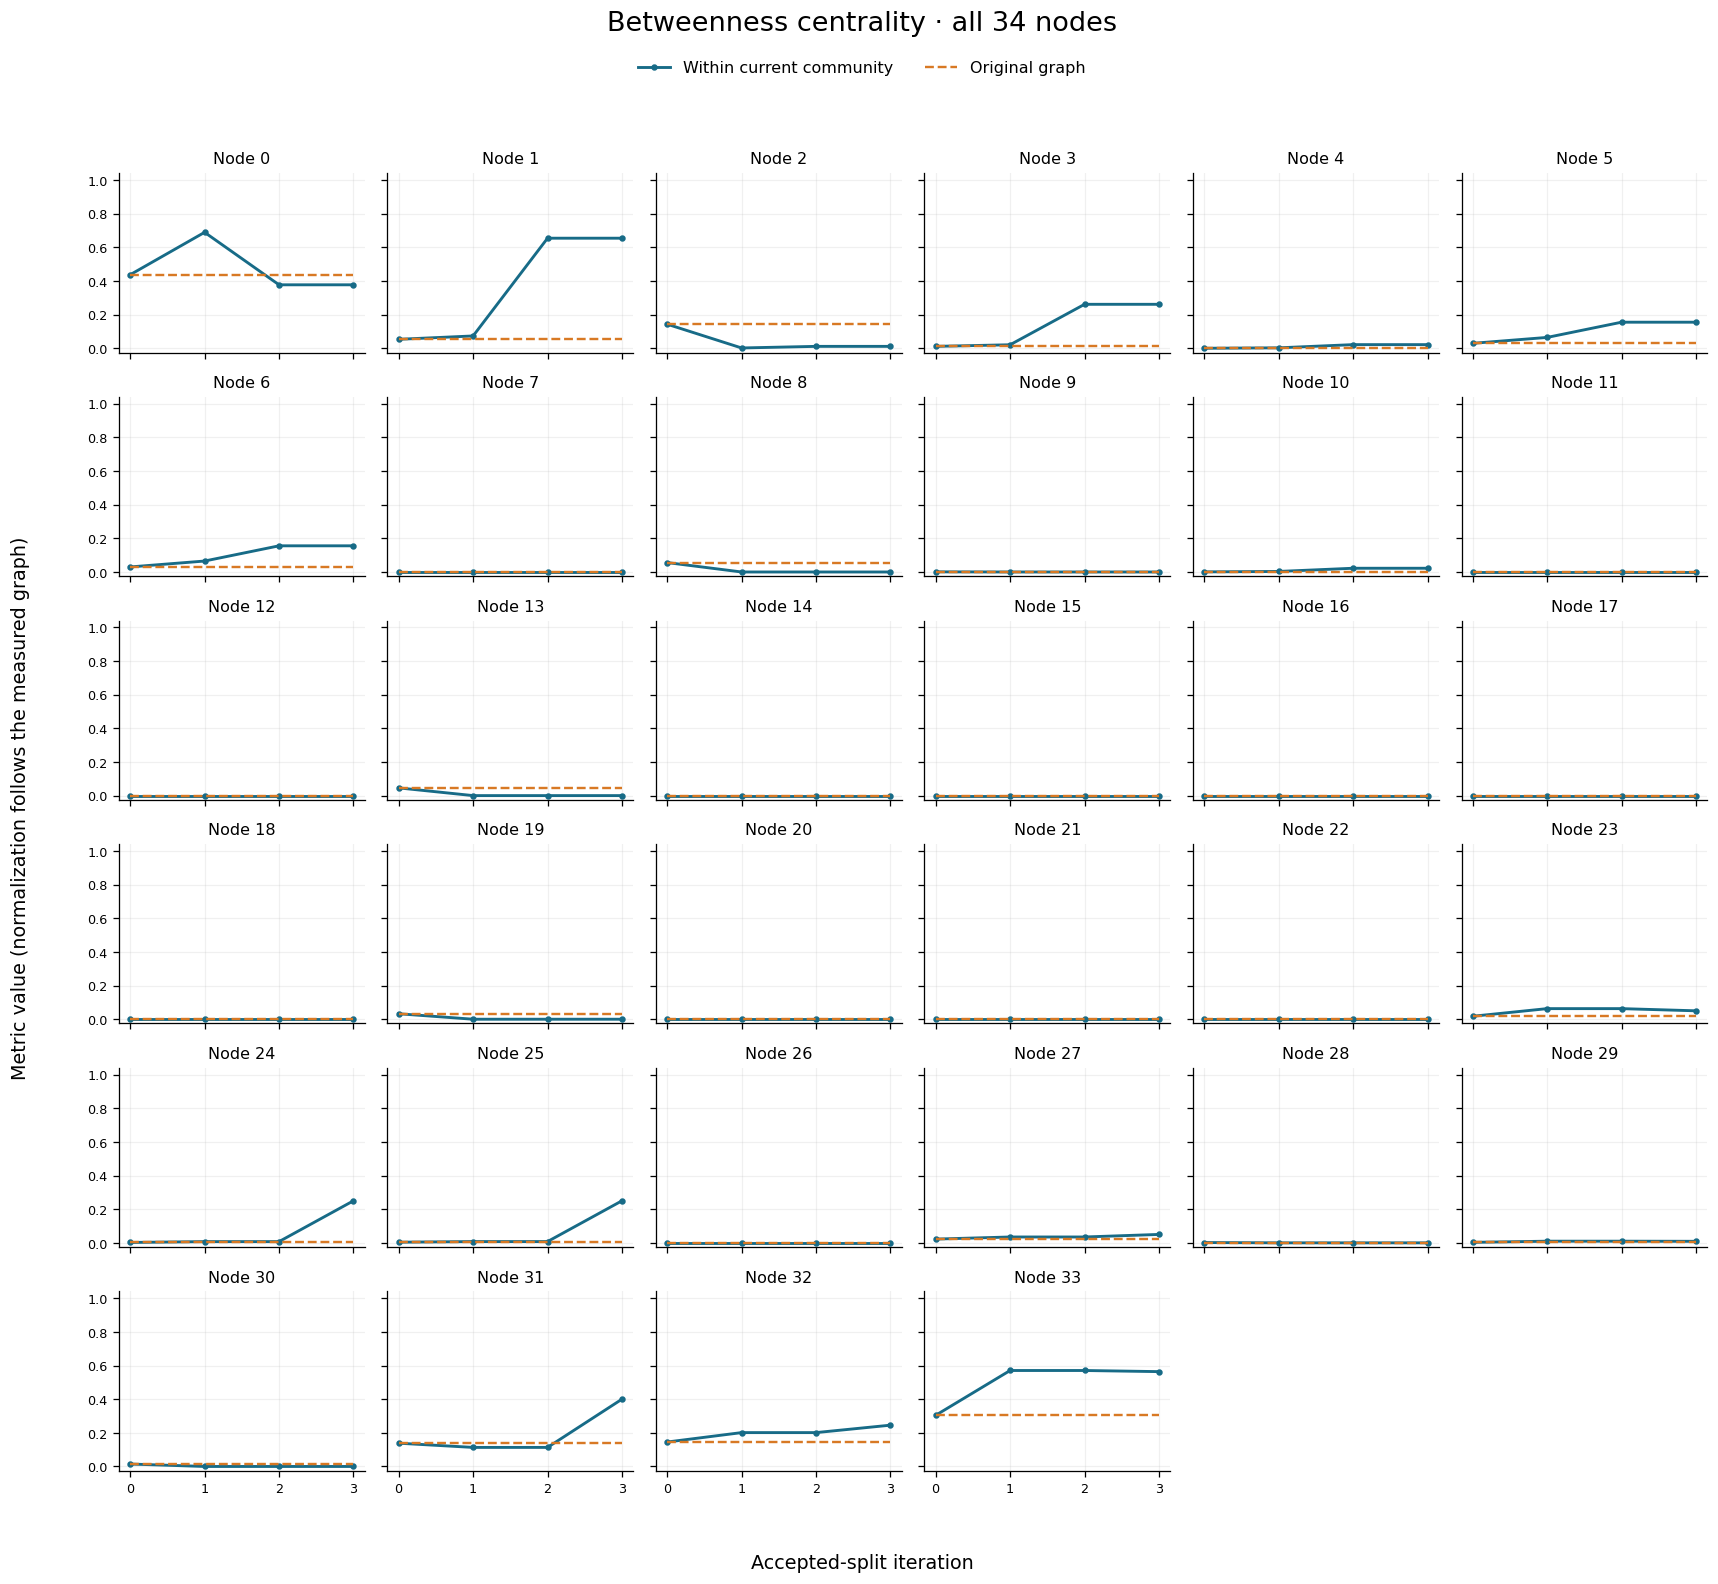

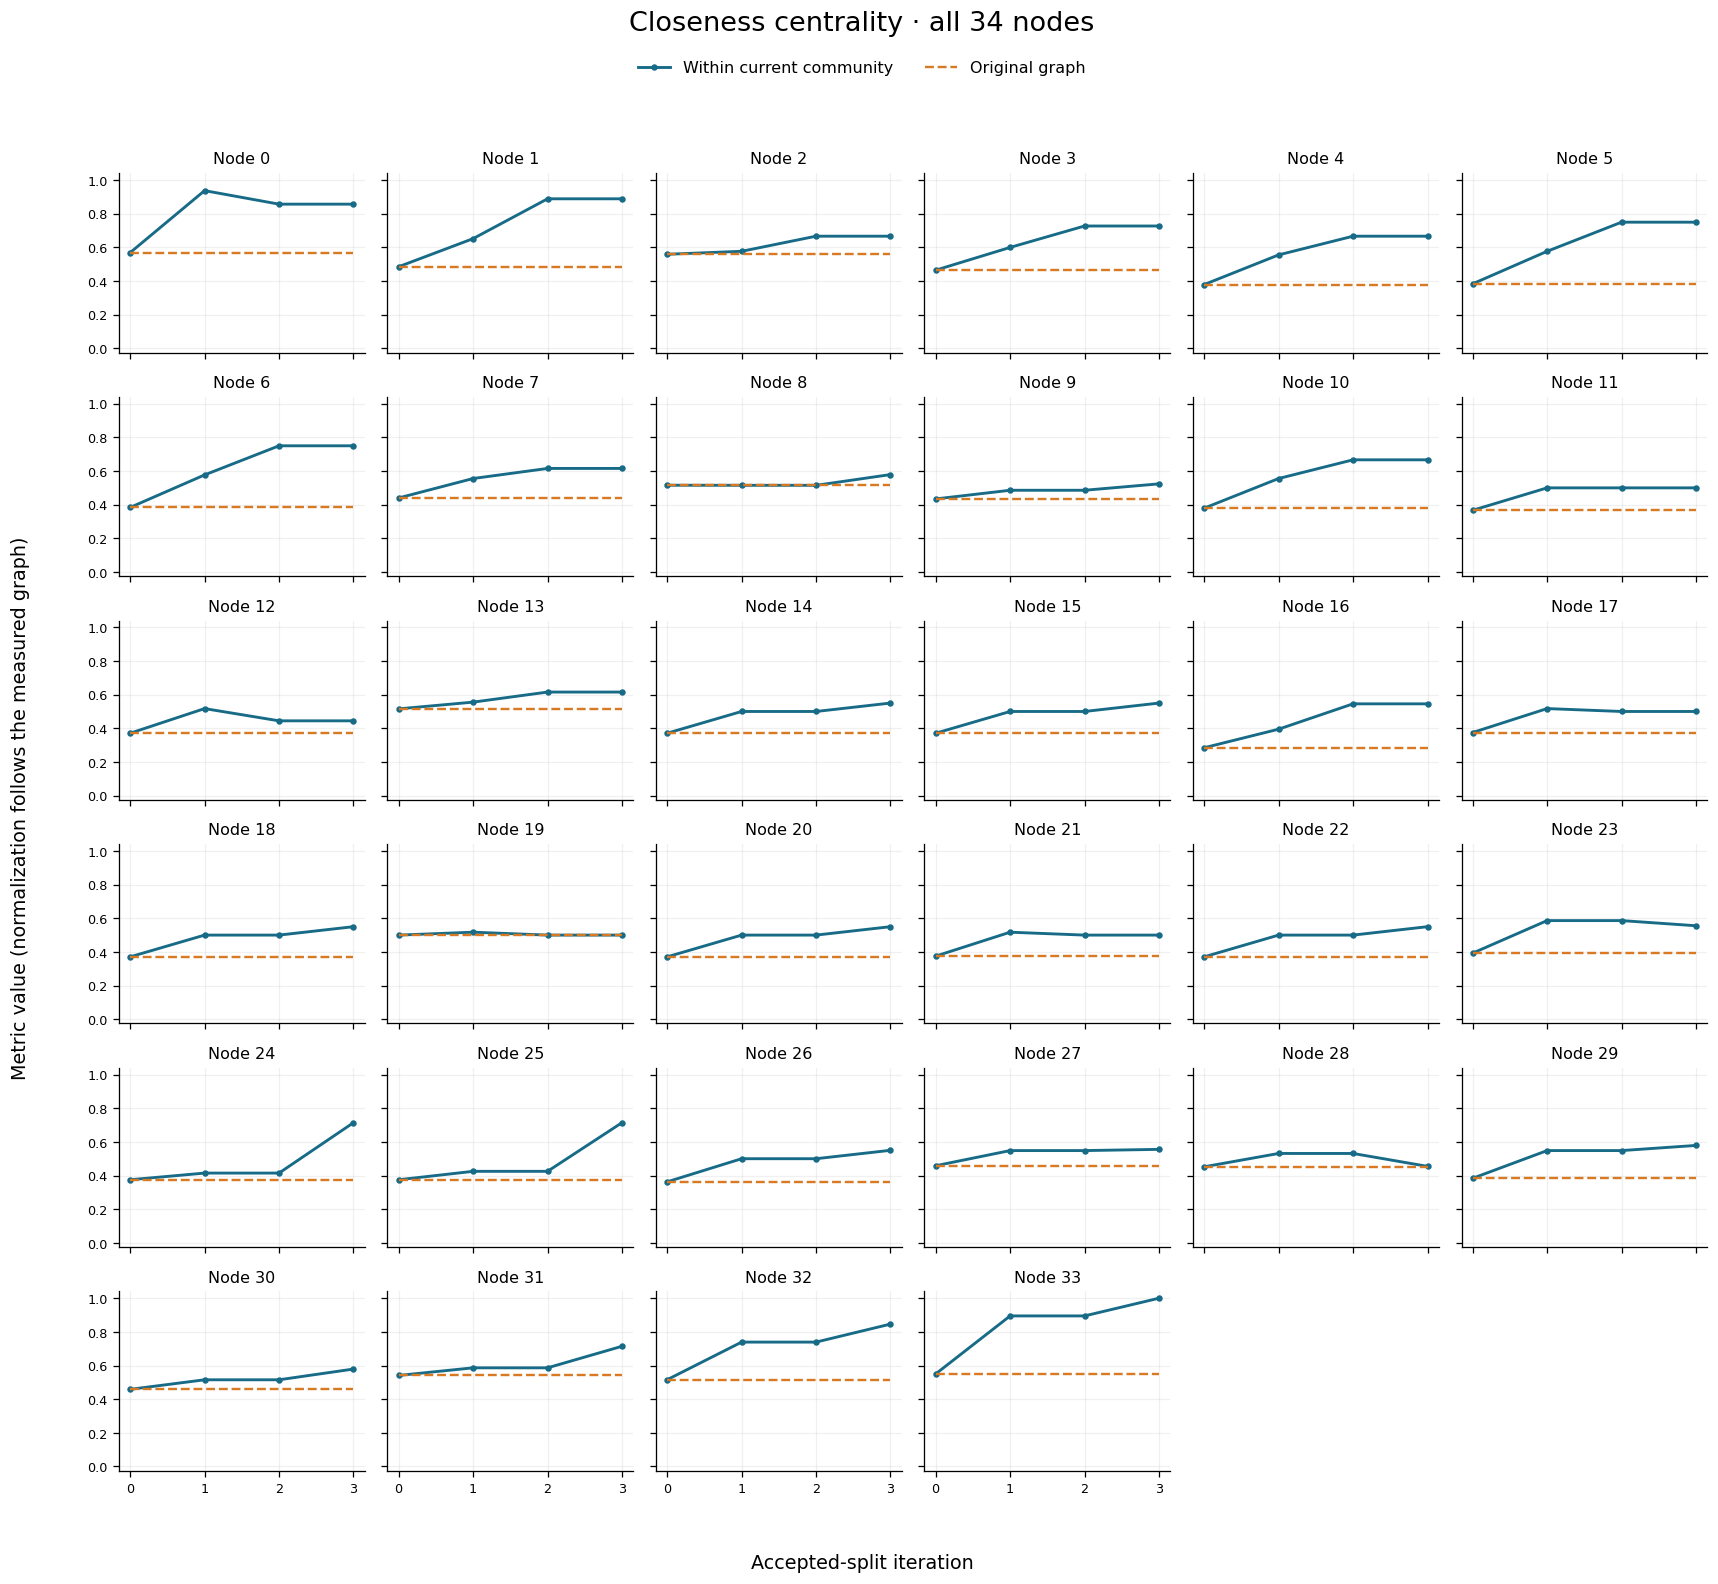

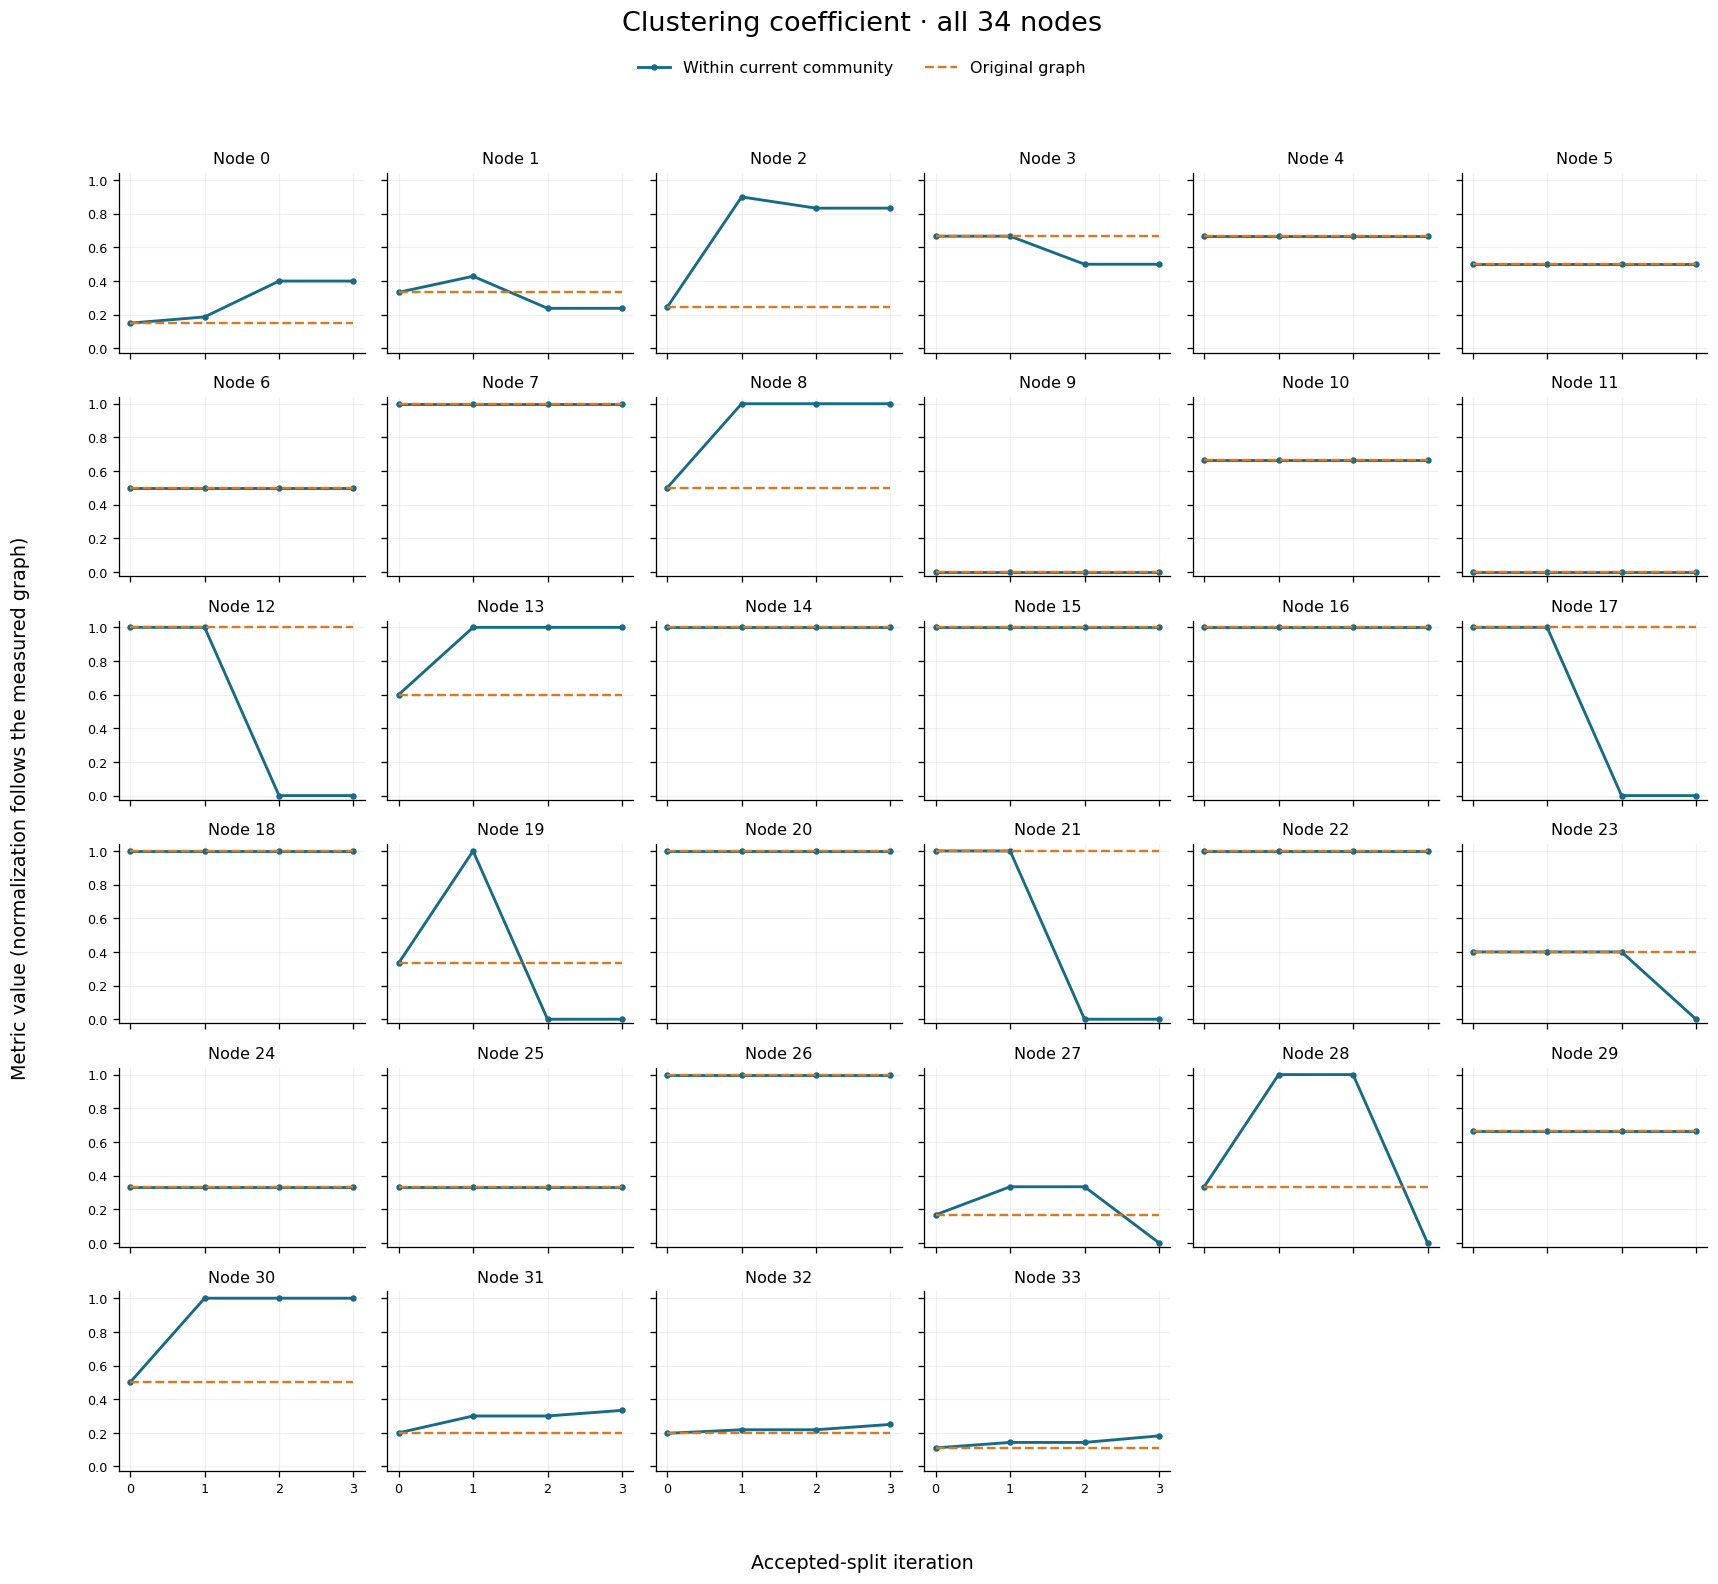

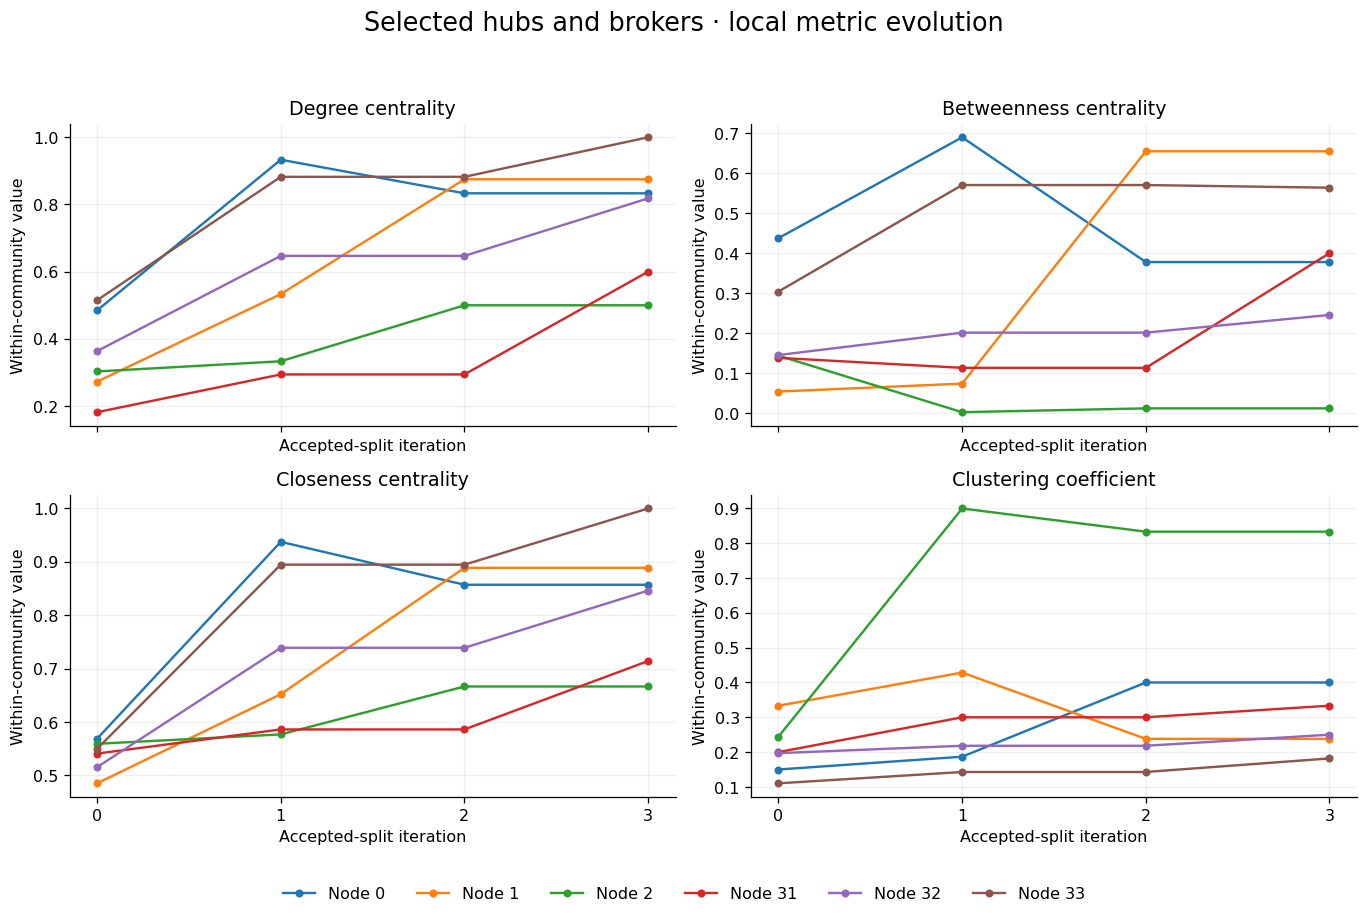

In [8]:
iterations = list(range(len(history)))
for metric in METRICS:
    fig, axes = plt.subplots(6, 6, figsize=(15, 14), sharex=True, sharey=True)
    for v, ax in zip(nodes, axes.flat):
        local_y = [local_metrics[t][metric][v] for t in iterations]
        global_y = [global_metrics[t][metric][v] for t in iterations]
        ax.plot(iterations, local_y, "o-", color="#176b87", linewidth=1.8, markersize=3)
        ax.plot(iterations, global_y, "--", color="#d87924", linewidth=1.5)
        ax.set_title(f"Node {v}", fontsize=10)
        ax.set_xticks(iterations); ax.set_ylim(-.025, 1.04); ax.grid(alpha=.18)
        ax.tick_params(labelsize=8)
    for ax in list(axes.flat)[n:]:
        ax.set_axis_off()
    fig.suptitle(f"{LABELS[metric]} · all 34 nodes", fontsize=17, y=.995)
    fig.supxlabel("Accepted-split iteration", y=.025)
    fig.supylabel("Metric value (normalization follows the measured graph)", x=.007)
    fig.legend(axes.flat[0].lines, ["Within current community", "Original graph"],
               loc="upper center", bbox_to_anchor=(.5,.973), ncol=2, frameon=False)
    fig.tight_layout(rect=(.02,.04,1,.945))
    fig.savefig(OUT / f"all_nodes_{metric}.png", bbox_inches="tight")
    plt.show()

focus_nodes = [0, 1, 2, 31, 32, 33]
fig, axes = plt.subplots(2, 2, figsize=(12,8), sharex=True)
for metric, ax in zip(METRICS, axes.flat):
    for v in focus_nodes:
        ax.plot(iterations, [local_metrics[t][metric][v] for t in iterations],
                "o-", label=f"Node {v}", markersize=4)
    ax.set_title(LABELS[metric]); ax.set_xticks(iterations)
    ax.set_xlabel("Accepted-split iteration"); ax.set_ylabel("Within-community value")
    ax.grid(alpha=.2)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center", ncol=6,
           frameon=False)
fig.suptitle("Selected hubs and brokers · local metric evolution", fontsize=16)
fig.tight_layout(rect=(0,.055,1,.95))
fig.savefig(OUT / "selected_nodes_evolution.png", bbox_inches="tight"); plt.show()

## 8. Results

The first table lists the final communities, their sizes, internal edges, and average clustering measured inside each community. The other tables compare selected nodes and identify the highest-scoring nodes in each group. Local scores use the size of the community for normalization, so scores from different groups need care when comparing.

In [9]:
community_summary = pd.DataFrame([
    {"community": cid, "nodes": list(C), "size": len(C),
     "internal_edges": G.subgraph(C).number_of_edges(),
     "mean_local_clustering": nx.average_clustering(G.subgraph(C))}
    for cid, C in sorted(final_partition.items())])
display(community_summary.round(4))
community_summary.to_csv(OUT / "community_summary.csv", index=False)
comparison = pd.DataFrame([
    {"node": v, "metric": LABELS[metric],
     "original_graph": global_metrics[0][metric][v],
     "final_community": local_metrics[history[-1]["iteration"]][metric][v]}
    for v in [0, 1, 2, 31] for metric in ["degree", "betweenness", "closeness"]])
display(comparison.round(4))
comparison.to_csv(OUT / "key_node_comparison.csv", index=False)

,community,nodes,size,internal_edges,mean_local_clustering
0,C00,"[0, 4, 5, 6, 10, 11, 16]",7,11,0.5333
1,C01,"[1, 2, 3, 7, 12, 13, 17, 19, 21]",9,13,0.3968
2,C10,"[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]",12,21,0.7582
3,C11,"[23, 24, 25, 27, 28, 31]",6,7,0.1667


,node,metric,original_graph,final_community
0,0,Degree centrality,0.4848,0.8333
1,0,Betweenness centrality,0.4376,0.3778
2,0,Closeness centrality,0.5690,0.8571
3,1,Degree centrality,0.2727,0.8750
4,1,Betweenness centrality,0.0539,0.6548
5,1,Closeness centrality,0.4853,0.8889
6,2,Degree centrality,0.3030,0.5000
7,2,Betweenness centrality,0.1437,0.0119
8,2,Closeness centrality,0.5593,0.6667
9,31,Degree centrality,0.1818,0.6000


In [10]:
last_t = history[-1]["iteration"]
selected = metrics_df[(metrics_df.scope == "within_community")
                      & metrics_df.node.isin(focus_nodes)]
display(selected[["iteration", "node", "community", *METRICS]].round(4)
        .reset_index(drop=True))
leaders = []
for cid, C in sorted(final_partition.items()):
    row = {"community": cid, "size": len(C)}
    for metric in METRICS:
        best = max(local_metrics[last_t][metric][v] for v in C)
        winners = [v for v in C if np.isclose(local_metrics[last_t][metric][v], best)]
        row[metric] = f"{winners} ({best:.4f})"
    leaders.append(row)
display(pd.DataFrame(leaders))
print("Original-graph top five for each metric:")
for metric in METRICS:
    ranking = sorted(global_metrics[0][metric].items(), key=lambda item: (-item[1],item[0]))
    print(metric, [(v,round(value,4)) for v,value in ranking[:5]])

Original-graph top five for each metric:
degree [(33, 0.5152), (0, 0.4848), (32, 0.3636), (2, 0.303), (1, 0.2727)]
betweenness [(0, 0.4376), (33, 0.3041), (32, 0.1452), (2, 0.1437), (31, 0.1383)]
closeness [(0, 0.569), (2, 0.5593), (33, 0.55), (31, 0.541), (8, 0.5156)]
clustering [(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0), (16, 1.0)]


,iteration,node,community,degree,betweenness,closeness,clustering
0,0,0,C,0.4848,0.4376,0.5690,0.1500
1,0,1,C,0.2727,0.0539,0.4853,0.3333
2,0,2,C,0.3030,0.1437,0.5593,0.2444
3,0,31,C,0.1818,0.1383,0.5410,0.2000
4,0,32,C,0.3636,0.1452,0.5156,0.1970
5,0,33,C,0.5152,0.3041,0.5500,0.1103
6,1,0,C0,0.9333,0.6897,0.9375,0.1868
7,1,1,C0,0.5333,0.0738,0.6522,0.4286
8,1,2,C0,0.3333,0.0024,0.5769,0.9000
9,1,31,C1,0.2941,0.1132,0.5862,0.3000


,community,size,degree,betweenness,closeness,clustering
0,C00,7,[0] (0.8333),[0] (0.3778),[0] (0.8571),[16] (1.0000)
1,C01,9,[1] (0.8750),[1] (0.6548),[1] (0.8889),"[7, 13] (1.0000)"
2,C10,12,[33] (1.0000),[33] (0.5636),[33] (1.0000),"[8, 14, 15, 18, 20, 22, 26, 30] (1.0000)"
3,C11,6,"[24, 25, 31] (0.6000)",[31] (0.4000),"[24, 25, 31] (0.7143)","[24, 25, 31] (0.3333)"


### Discussion

Three accepted splits produce four communities of sizes 7, 9, 12, and 6. Modularity rises from 0 to 0.371466, then 0.372699, and finally 0.393409. The second increase is small, but it is still positive.

The first split agrees with the historical club labels for 33 out of 34 nodes. Node 8 is placed on the other side. The final four groups describe smaller communities inside the network, whereas the historical labels describe two factions. These are different ways of grouping the members.

In the original graph, nodes 33 and 0 have the highest degrees, with 17 and 16 neighbours. Node 0 has the highest betweenness. These global values stay constant because assigning community labels does not change the original graph.

The local measurements show a different picture. Node 0 remains the main hub and connector in C00. Node 1 becomes the main connector in C01, and its normalized betweenness changes from 0.0539 in the full graph to 0.6548 inside its community. Node 2 shows the opposite pattern: its betweenness falls from 0.1437 to 0.0119 when paths outside its community are excluded. Node 31 becomes the main connector in C11, with local betweenness 0.4000 compared with 0.1383 globally. Both the available paths and the normalization change in these comparisons.

The average within-community clustering values are 0.5333, 0.3968, 0.7582, and 0.1667 for C00, C01, C10, and C11 respectively. C10 therefore has the greatest average neighbour cohesion. A high clustering coefficient does not necessarily mean a node is an important connector: even a node with only two neighbours has clustering 1 if those neighbours are connected.

For C01, the leading eigenvalue is positive (about 0.06019), but splitting by the eigenvector signs gives a negative gain (about -0.01578). The split is rejected. This shows why checking the actual gain is necessary.

The checks in Appendix B find no improving bisection within any final community. This does not prove that the final partition is the best possible one: the method does not reconsider earlier splits or move nodes between existing groups.

## 9. References

1. **Newman, M. E. J. (2006).** “Modularity and community structure in networks.” *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. [doi:10.1073/pnas.0601602103](https://doi.org/10.1073/pnas.0601602103). Method attribution: modularity matrix, leading-eigenvector partitioning, and generalized subgroup matrix (equations 5–6).
2. **Zachary, W. W. (1977).** “An Information Flow Model for Conflict and Fission in Small Groups.” *Journal of Anthropological Research*, 33, 452–473. Dataset obtained through [NetworkX `karate_club_graph`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html). NetworkX labels nodes from 0; the original paper uses labels starting at 1.
3. **NetworkX documentation:** [modularity](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.quality.modularity.html), [degree centrality](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.degree_centrality.html), [betweenness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality.html), [closeness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.closeness_centrality.html), and [clustering](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.cluster.clustering.html).
4. **DSC212 course handout:** *Research Assignment: Modularity on the Karate Club Graph*, supplied assignment PDF. Requirements and notation are taken from this handout; the recursive-gain ambiguity is addressed in Section 2.

The following cell exports every metric value, the split history, terminal checks, community membership, and dependency versions. The figures have already been saved by earlier cells. No internet access is needed when rerunning the notebook after dependencies are installed.

## Appendix A. Derivation and stopping rule


For a partition $\mathcal P$, let $c_i$ be the community containing vertex $i$. Define
\[
B_{ij}=A_{ij}-\frac{k_i k_j}{2m},\qquad
Q(\mathcal P)=\frac{1}{2m}\sum_{i,j}B_{ij}\,\mathbf1(c_i=c_j).
\]
The first term counts observed connections; the second is the conventional degree-based null-model baseline. Thus a positive score means more within-community connectivity than this baseline predicts. It is a quality score, **not a statistical significance test**.

An equivalent formula useful for checking the result is
\[
Q(\mathcal P)=\sum_{C\in\mathcal P}
\left[\frac{L_C}{m}-\left(\frac{K_C}{2m}\right)^2\right],
\]
where $L_C$ counts edges internal to $C$ once, and $K_C=\sum_{i\in C}k_i$ uses degrees from the **original graph**.

### Why the two-group formula has a factor of $1/(4m)$
For labels $s_i\in\{-1,+1\}$, two vertices share a group exactly when $(1+s_i s_j)/2=1$. Substituting this into $Q$ gives
\[
Q=\frac{1}{4m}\sum_{ij}B_{ij}
  +\frac{1}{4m}\sum_{ij}B_{ij}s_i s_j
  =\frac{1}{4m}s^\top Bs.
\]
The first sum is zero because
$\sum_j B_{ij}=k_i-k_i\sum_jk_j/(2m)=0$.
In particular, keeping every node together gives $Q=0$.

### The recursive correction
The handout's Section 3.3/Theorem 3 identifies a raw submatrix with the gain matrix, while Section 4 refers to recomputing modularity on an induced subgraph. These are different operations. To optimize **one global modularity objective**, retain the original $k_i$ and $m$.

For a current community $C$, write $R=B[C,C]$. Before splitting, all pairs in $C$ contribute; afterwards only pairs with matching signs contribute. Subtracting the old contribution from the new one gives
\[
\Delta Q=\frac{1}{4m}\left(s^\top Rs-\mathbf1^\top R\mathbf1\right).
\]
Since $s_i^2=1$, define
\[
\boxed{M_C=R-\operatorname{diag}(R\mathbf1)},\qquad
\boxed{\Delta Q=\frac{1}{4m}s^\top M_Cs}.
\]
This is Newman's generalized modularity matrix [1, equations 5–6]. It has zero row sums and yields zero gain for an unsplit group. For $C=V$ it reduces to $B$. Using only $s^\top Rs/(4m)$ omits the previous community's contribution. Recomputing local degrees and local edge counts instead changes the optimization objective.

### Why an eigenvector is used, and when to stop
A sign vector has $\|s\|^2=|C|$. Relax the discrete constraint to the sphere $\|x\|^2=|C|$. If $x=\sum_r a_ru_r$ in an orthonormal eigenbasis of the real symmetric $M_C$, then
\[
x^\top M_Cx=\sum_r\lambda_r a_r^2
\leq\lambda_{\max}\sum_ra_r^2
=|C|\lambda_{\max}.
\]
The relaxed optimum is attained by $\sqrt{|C|}u_{\max}$; the scaling does not affect signs. We obtain a candidate discrete split from the signs of $u_{\max}$.

- If $\lambda_{\max}\leq0$, no split can increase modularity.
- If $\lambda_{\max}>0$, rounding to signs is still a heuristic: **check the actual $\Delta Q$**.
- Reject empty groups, nonpositive gains, and numerically negligible gains.
- Stopping after a rejected sign split does not generally prove that every discrete split is bad. Here an additional small exhaustive check of the final groups is feasible.

We use a tolerance of $10^{-10}$. An arbitrary eigenvector sign is fixed for reproducibility, and child groups are ordered by minimum node ID. Recursion is depth-first. One **iteration** means one accepted split, not one eigenvalue calculation.

## Appendix B. Exhaustive terminal checks
For each final community, test every nontrivial bipartition while keeping other groups fixed. This certifies no further improving bisection inside these groups, not global optimality.

In [11]:
terminal_checks = []
for cid, C in sorted(final_partition.items()):
    _, M = corrected_block(C)
    gains = []
    for tail in itertools.product((-1, 1), repeat=len(C)-1):
        s = np.array((1,) + tail)
        if np.all(s == 1):
            continue
        gains.append(float(s @ M @ s/(4*m)))
    best = max(gains) if gains else 0.0
    terminal_checks.append({"community": cid, "tested_nontrivial_splits": len(gains),
                            "best_nontrivial_gain": best})
    assert best <= TOL
terminal_df = pd.DataFrame(terminal_checks)
display(terminal_df.round(8))
print("PASS: all partitions valid, modularity formulas agree, accepted gains positive,")
print("and no final community admits a positive-gain bisection.")



PASS: all partitions valid, modularity formulas agree, accepted gains positive,
and no final community admits a positive-gain bisection.


,community,tested_nontrivial_splits,best_nontrivial_gain
0,C00,63,-0.010191
1,C01,255,-0.002959
2,C10,2047,-0.003945
3,C11,31,-0.007643


In [12]:
summary.to_csv(OUT / "split_history.csv", index=False)
attempts.to_csv(OUT / "split_attempts.csv", index=False)
metrics_df.to_csv(OUT / "node_metrics_all_iterations.csv", index=False)
terminal_df.to_csv(OUT / "terminal_bisection_checks.csv", index=False)
pd.DataFrame(leaders).to_csv(OUT / "final_community_leaders.csv", index=False)
(OUT / "communities.json").write_text(json.dumps(
    {cid:list(C) for cid,C in sorted(final_partition.items())}, indent=2))
(OUT / "partition_history.json").write_text(json.dumps(history, indent=2))
versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "networkx": nx.__version__, "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2))
print("Finished. All checks passed; figures and complete results written to:", OUT.as_posix())

Finished. All checks passed; figures and complete results written to: results
